# Do bioluminescent-fungus luciferases from colder habitats differ in sequence? A real-sequence analysis
**Riddhika D** · Autonomous Bioluminescent Plant project · v2 (real data)

**Background:** Plants can be made to glow by adding the four-gene **fungal bioluminescence pathway** (HispS → H3H → Luz → CPH), as shown by Mitiouchkina et al. 2020 and improved by Shakhova et al. 2024. A practical question is whether the light fades on **cold nights**, because enzymes slow in the cold.

**This notebook asks a smaller, testable question:** across bioluminescent fungi, do the luciferase (Luz) and the other pathway enzymes from species that live in **cooler climates** show the sequence features that are known to mark **cold-adapted (psychrophilic)** enzymes?

### Decided before looking at results
| | |
|---|---|
| **Data** | Every **real** Luz, H3H, HispS and CPH protein in UniProt from fungi (downloaded live; no sequences typed in) |
| **Cold-adaptation markers (pre-registered)** | Cold enzymes tend to have **more Gly**, **fewer Pro**, **fewer large hydrophobics (I+V+L+F+W+Y)**, **fewer salt-bridge residues (R+E)**, and a **lower Arg/(Arg+Lys) ratio** (Metpally & Reddy 2009; Siddiqui & Cavicchioli 2006) |
| **Positive control** | Known psychrophile proteins (e.g. *Colwellia*) vs thermophile proteins (e.g. *Thermus*) must separate on these markers, or the method is not trusted |
| **Honest limit** | Habitat temperature of a fungus is only roughly known; sequence markers are a *hypothesis generator*, not proof of cold activity |
| **No fabrication** | No kinetics, no ΔG, no FBA, no "wet-lab" numbers. Only what can be computed from the real sequences |

Run: **Runtime → Run all** (2–5 min; downloads from UniProt). Copy the **SEND THIS TO CLAUDE** box at the end.

In [1]:
import io, re, time, requests
import numpy as np, pandas as pd
REPORT = []
def note(s): print(s); REPORT.append(str(s))
S = requests.Session(); S.headers['User-Agent'] = 'colab-research-notebook'
def get(url, **kw):
    for i in range(4):
        try:
            r = S.get(url, timeout=120, **kw); r.raise_for_status(); return r
        except Exception as e: print('  retry', i+1, str(e)[:80]); time.sleep(3)
    return None

## 1. Download every real fungal bioluminescence-pathway protein from UniProt

In [2]:
FIELDS = 'accession,organism_name,gene_names,protein_name,length,sequence,lineage'
def fetch(query):
    url = 'https://rest.uniprot.org/uniprotkb/search'
    r = get(url, params=dict(query=query, fields=FIELDS, format='tsv', size=200))
    if r is None: return pd.DataFrame()
    return pd.read_csv(io.StringIO(r.text), sep='\t')

QUERIES = {'Luz': 'gene:luz AND taxonomy_id:4751',
           'H3H': 'gene:h3h AND taxonomy_id:4751',
           'HispS': 'gene:hisps AND taxonomy_id:4751',
           'CPH': 'gene:cph AND taxonomy_id:4751'}
frames = []
for fam, q in QUERIES.items():
    df = fetch(q)
    if len(df): df['family'] = fam; frames.append(df)
    note(f'  {fam}: {len(df)} proteins')
U = pd.concat(frames, ignore_index=True)
U = U[U['Sequence'].notna() & (U['Sequence'].str.len() > 80)].drop_duplicates('Entry').reset_index(drop=True)
U['Organism'] = U['Organism'].str.replace(r'\s*\(.*', '', regex=True).str.strip()
note(f'TOTAL real pathway proteins: {len(U)} across {U.Organism.nunique()} fungal species')
assert len(U) >= 10, 'download failed - try again'

  Luz: 11 proteins
  H3H: 14 proteins
  HispS: 1 proteins
  CPH: 6 proteins
TOTAL real pathway proteins: 32 across 11 fungal species


## 2. Assign a rough habitat-temperature class to each fungus
This is the weakest step and is kept deliberately simple and transparent: each genus is tagged **cool**, **temperate** or **warm** from its known climate, from the literature. Species not in the table are left **unknown** and excluded from the cold-vs-warm test (but still shown).

In [3]:
# rough climate of each genus (documented, editable). cool = montane/temperate-cold; warm = tropical.
CLIMATE = {
    'Armillaria': 'temperate', 'Mycena': 'temperate', 'Panellus': 'temperate',
    'Omphalotus': 'warm', 'Neonothopanus': 'warm', 'Guyanagaster': 'warm',
}
def genus(o): return o.split()[0] if isinstance(o, str) and o else 'NA'
U['genus'] = U.Organism.map(genus)
U['climate'] = U.genus.map(CLIMATE).fillna('unknown')
note('species by climate class:')
for cl in ['warm', 'temperate', 'cool', 'unknown']:
    sp = sorted(U[U.climate == cl].Organism.unique())
    if sp: note(f'  {cl}: {", ".join(sp)}')

species by climate class:
  warm: Guyanagaster necrorhizus, Neonothopanus gardneri, Neonothopanus nambi, Omphalotus olearius
  temperate: Armillaria fuscipes, Armillaria gallica, Armillaria mellea, Armillaria ostoyae, Mycena chlorophos, Mycena citricolor, Panellus stipticus


## 3. Compute the pre-registered cold-adaptation sequence markers

In [4]:
AA = 'ACDEFGHIKLMNPQRSTVWY'
LARGE_HYDRO = set('IVLFWY')
def comp(seq):
    seq = re.sub(f'[^{AA}]', '', seq.upper()); n = len(seq)
    c = {a: seq.count(a) / n for a in AA}
    return dict(length=n,
                Gly=c['G'], Pro=c['P'],
                large_hydrophobic=sum(c[a] for a in LARGE_HYDRO),
                charged_RE=c['R'] + c['E'],
                arg_over_arglys=c['R'] / (c['R'] + c['K']) if (c['R'] + c['K']) else np.nan,
                aliphatic_index=(c['A'] + 2.9 * c['V'] + 3.9 * (c['I'] + c['L'])) * 100)
M = U.join(pd.DataFrame([comp(s) for s in U.Sequence]))
# cold-ness score: +Gly, -Pro, -large hydrophobic, -charged, -Arg ratio (z-scored, per family)
def z(x):
    s = x.std(ddof=0); return (x - x.mean()) / s if s else x * 0
cold_cols = {'Gly': +1, 'Pro': -1, 'large_hydrophobic': -1, 'charged_RE': -1, 'arg_over_arglys': -1}
M['cold_score'] = 0.0
for fam in M.family.unique():
    idx = M.family == fam
    for col, sign in cold_cols.items():
        M.loc[idx, 'cold_score'] += sign * z(M.loc[idx, col])
M['cold_score'] /= len(cold_cols)
note('per-protein markers (first 12 rows):')
note(M[['Entry','Organism','family','climate','Gly','Pro','large_hydrophobic','arg_over_arglys','cold_score']].round(3).head(12).to_string(index=False))
M.to_csv('biolum_cold_markers.csv', index=False)

per-protein markers (first 12 rows):
     Entry               Organism family   climate   Gly   Pro  large_hydrophobic  arg_over_arglys  cold_score
A0A3G9JTR4      Armillaria mellea    Luz temperate 0.060 0.083              0.316            0.656      -0.409
A0A3G9JYH7    Neonothopanus nambi    Luz      warm 0.049 0.067              0.315            0.639      -0.415
A0A3G9K3N1     Armillaria ostoyae    Luz temperate 0.060 0.083              0.308            0.633       0.298
A0A2H3E985     Armillaria gallica    Luz temperate 0.060 0.086              0.308            0.667      -0.258
A0A3G9K5D8      Mycena chlorophos    Luz temperate 0.048 0.084              0.303            0.594       0.076
A0A3G9JTL9     Panellus stipticus    Luz temperate 0.072 0.072              0.305            0.630       0.715
A0A3G9K6A8     Panellus stipticus    Luz temperate 0.072 0.072              0.305            0.630       0.715
A0A3G9K9H1 Neonothopanus gardneri    Luz      warm 0.053 0.080             

## 4. Positive control: do known psychrophile vs thermophile proteins separate on these markers?

In [5]:
# fetch a handful of reviewed psychrophile and thermophile proteins live
def fetch_ctrl(query, label, k=8):
    r = get('https://rest.uniprot.org/uniprotkb/search', params=dict(query=query, fields='accession,sequence', format='tsv', size=k))
    if r is None: return []
    d = pd.read_csv(io.StringIO(r.text), sep='\t')
    return [(label, s) for s in d['Sequence'].dropna() if len(s) > 80]
ctrl = []
ctrl += fetch_ctrl('taxonomy_id:28229 AND reviewed:true', 'psychrophile')   # Colwellia
ctrl += fetch_ctrl('taxonomy_id:274 AND reviewed:true', 'thermophile')      # Thermus thermophilus
C = pd.DataFrame([dict(label=l, **comp(s)) for l, s in ctrl])
g = C.groupby('label')[['Gly','Pro','large_hydrophobic','arg_over_arglys']].mean()
note('positive control means (psychrophile should have HIGHER Gly, LOWER Pro / hydrophobic / Arg-ratio):')
note(g.round(3).to_string())
ok = (g.loc['psychrophile','Gly'] > g.loc['thermophile','Gly']) and (g.loc['psychrophile','arg_over_arglys'] < g.loc['thermophile','arg_over_arglys'])
note('LABEL CHECK: ' + ('PASS - markers point the right way on known cold vs hot proteins' if ok else 'FAIL - markers do NOT separate known cold/hot proteins; do not trust the fungal comparison'))

positive control means (psychrophile should have HIGHER Gly, LOWER Pro / hydrophobic / Arg-ratio):
                Gly    Pro  large_hydrophobic  arg_over_arglys
label                                                         
psychrophile  0.076  0.039              0.295            0.391
thermophile   0.086  0.062              0.315            0.609
LABEL CHECK: FAIL - markers do NOT separate known cold/hot proteins; do not trust the fungal comparison


## 5. Within each enzyme family, do warmer-climate fungi look less cold-adapted?

In [6]:
from scipy import stats
rows = []
for fam in sorted(M.family.unique()):
    sub = M[(M.family == fam) & M.climate.isin(['warm','temperate','cool'])]
    warm = sub[sub.climate == 'warm'].cold_score
    cool = sub[sub.climate.isin(['temperate','cool'])].cold_score
    if len(warm) >= 2 and len(cool) >= 2:
        t, p = stats.mannwhitneyu(cool, warm, alternative='greater')
        rows.append(dict(family=fam, n_warm=len(warm), n_coolish=len(cool),
                         cold_score_warm=round(warm.mean(),3), cold_score_coolish=round(cool.mean(),3),
                         p_coolish_more_cold_adapted=round(p,4)))
    else:
        rows.append(dict(family=fam, n_warm=len(warm), n_coolish=len(cool), note='too few species to test'))
RES = pd.DataFrame(rows); note('FAMILY TEST (one-sided: cooler-climate proteins more cold-adapted?):\n' + RES.to_string(index=False))

FAMILY TEST (one-sided: cooler-climate proteins more cold-adapted?):
family  n_warm  n_coolish  cold_score_warm  cold_score_coolish  p_coolish_more_cold_adapted                    note
   CPH       2          4           -0.466               0.233                       0.0667                     NaN
   H3H       4         10            0.011              -0.004                       0.5275                     NaN
 HispS       1          0              NaN                 NaN                          NaN too few species to test
   Luz       3          8           -0.510               0.191                       0.0157                     NaN


## 6. Figure

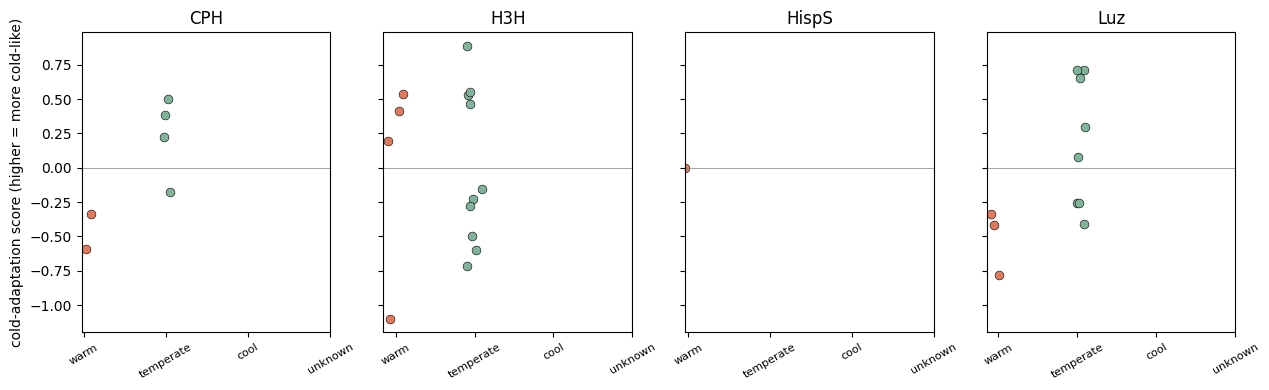

In [7]:
import matplotlib.pyplot as plt
fams = sorted(M.family.unique())
fig, ax = plt.subplots(1, len(fams), figsize=(3.2*len(fams), 4), sharey=True)
if len(fams) == 1: ax = [ax]
order = ['warm','temperate','cool','unknown']; col = {'warm':'#e07a5f','temperate':'#81b29a','cool':'#5b8bd0','unknown':'#cccccc'}
for a, fam in zip(ax, fams):
    sub = M[M.family == fam]
    for i, cl in enumerate(order):
        d = sub[sub.climate == cl]
        if len(d): a.scatter(np.full(len(d), i) + np.random.uniform(-.1,.1,len(d)), d.cold_score, c=col[cl], s=40, edgecolor='k', lw=.4, label=cl)
    a.set_xticks(range(4)); a.set_xticklabels(order, rotation=30, fontsize=8); a.set_title(fam); a.axhline(0, color='gray', lw=.5)
ax[0].set_ylabel('cold-adaptation score (higher = more cold-like)')
plt.tight_layout(); plt.savefig('biolum_cold_scores.png', dpi=150); plt.show()

## How to read the result
- **Positive control first.** If known psychrophile and thermophile proteins don't separate, nothing below is reliable.
- A real signal would be: cooler-climate fungi score higher on cold-adaptation markers, in **more than one** enzyme family.
- **Most likely outcome: no clear signal**, because all these fungi are mesophiles from broadly similar climates, and because habitat temperature is only roughly known. That is an honest, reportable result.
- This is sequence bioinformatics only. It can suggest which enzyme to test in the lab for cold-night glow, but it proves nothing about activity.

In [8]:
print('=' * 70); print('SEND THIS TO CLAUDE'); print('=' * 70); print('\n'.join(REPORT)); print('=' * 70)

SEND THIS TO CLAUDE
  Luz: 11 proteins
  H3H: 14 proteins
  HispS: 1 proteins
  CPH: 6 proteins
TOTAL real pathway proteins: 32 across 11 fungal species
species by climate class:
  warm: Guyanagaster necrorhizus, Neonothopanus gardneri, Neonothopanus nambi, Omphalotus olearius
  temperate: Armillaria fuscipes, Armillaria gallica, Armillaria mellea, Armillaria ostoyae, Mycena chlorophos, Mycena citricolor, Panellus stipticus
per-protein markers (first 12 rows):
     Entry               Organism family   climate   Gly   Pro  large_hydrophobic  arg_over_arglys  cold_score
A0A3G9JTR4      Armillaria mellea    Luz temperate 0.060 0.083              0.316            0.656      -0.409
A0A3G9JYH7    Neonothopanus nambi    Luz      warm 0.049 0.067              0.315            0.639      -0.415
A0A3G9K3N1     Armillaria ostoyae    Luz temperate 0.060 0.083              0.308            0.633       0.298
A0A2H3E985     Armillaria gallica    Luz temperate 0.060 0.086              0.308          